In [ ]:
# Урок 41 АБ тестирование

In [22]:
import pandas as pd
import numpy as np
import random as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import norm
from scipy.stats import t

In [23]:
np.random.seed(105)
test = [i for i in np.random.normal(200, 60, 100) if i > 0]
control = [i for i in np.random.normal(170, 80, 100) if i > 0]

In [24]:
test_mean = np.mean(test)
conrtol_mean = np.mean(control)

test_std = np.std(test, ddof=1)
control_std = np.std(control, ddof=1)

test_size = len(test)
control_size = len(control)

dof = test_size + control_size - 2

err_diff = np.sqrt(test_std**2/test_size + control_std**2/control_size)
diff_mean = test_mean - conrtol_mean

In [25]:
t_stat = diff_mean/ err_diff
t_stat

1.2749823880997215

In [26]:
1 - t.cdf(t_stat, dof)

0.10190855931939691

In [27]:
t025, t975, t95 = t.ppf([0.025, 0.95, 0.95], dof)

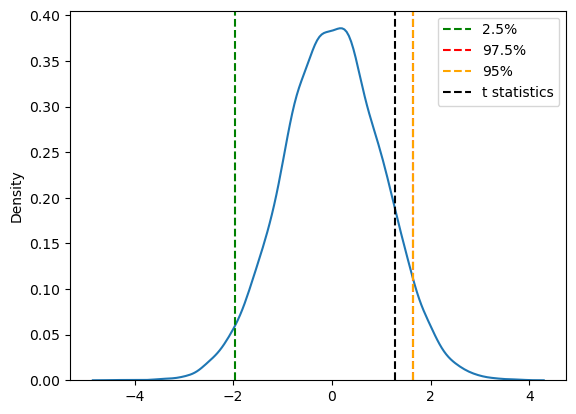

In [28]:
np.random.seed(105)
demonstration_data = np.random.standard_t(dof,10000)
sns.kdeplot(demonstration_data)

plt.axvline(t025, linestyle='--', label ='2.5%', color ='green')
plt.axvline(t975, linestyle='--', label ='97.5%', color ='red')

plt.axvline(t95, linestyle='--', label ='95%', color ='orange')

plt.axvline(t_stat, linestyle='--', label ='t statistics', color ='black')

plt.legend()
plt.show()

In [ ]:
# Урок 42 АБ тестирование (продолжение)

In [29]:
z_alp, z_bet = norm.ppf([0.025, 0.2])
z_alp, z_bet

(-1.9599639845400545, -0.8416212335729142)

In [30]:
err_diff

10.482428087261423

In [33]:
(2 * (z_alp+z_bet)**2*err_diff**2)/3**2

191.65446617814717

In [ ]:
# Урок 43 Что такое статистические тесты и для чего они нужны

In [ ]:
# Урок 44 Тест Манна Уитни

In [ ]:
# Урок 45 Тест Манна Уитни (продолжение)

In [35]:
import numpy as np
from scipy.stats import mannwhitneyu

In [38]:
# Назначаем random seed
np.random.seed(105)

# Синтезируем данные для Региона А
region_a =  np.append(np.random.randint(1, 4, 25), np.random.randint(4, 6, 25))

# Синтезируем данные для региона В
region_b =  np.append(np.random.randint(1, 4, 18), np.random.randint(4, 6, 32))

In [40]:
# Проводим Mann-Whitneyu test
u_statistic, p_value = mannwhitneyu(region_a, region_b, alternative='two-sided')


In [41]:
# Смотрим результат
print("\nMann-Whitneyu U :")
print("U Statistic:",u_statistic)
print("P-Value:", p_value)

# Интерпритация
alpha = 0.1
if p_value < alpha:
    print("\nВывод существует значительная разница в показателях удовлетворенности между регионом А и регионом Б:")
else:
    print("\nВывод существенной  разницы в показателях удовлетворенности между регионом А и регионом Б нет.")


Mann-Whitneyu U :
U Statistic: 1067.0
P-Value: 0.1949995417406022

Вывод существенной  разницы в показателях удовлетворенности между регионом А и регионом Б нет.


In [ ]:
# Урок 46 Тест Колмогорова-Смирнова

In [ ]:
# Урок 47 Тест Колмогорова-Смирнова (продолжение)

In [42]:
from scipy.stats import kstest
import numpy as np

In [43]:
np.random.seed(105)
sample = np.random.normal(loc=0, scale=1, size=100)

In [44]:
ks_statistic, p_value = kstest(sample, 'norm')

In [45]:
print(f"KS Statistic: {ks_statistic}")
print(f"P-value: {p_value}")

KS Statistic: 0.09145904750849598
P-value: 0.35148226704209695


In [56]:
from scipy.stats import ks_2samp

In [57]:
np.random.seed(105)
sample1 = np.random.normal(loc=0, scale=1, size=1000)
sample2 = np.random.normal(loc=1, scale=1, size=1000)

In [59]:
ks_statistic, p_value = ks_2samp(sample1, sample2)

In [60]:
print(f"KS Statistic: {ks_statistic}")
print(f"P-value: {p_value}")

KS Statistic: 0.365
P-value: 1.3022098987478291e-59


In [ ]:
# Урок 48 Тест Шапиро Уилка

In [66]:
import numpy as np
from scipy.stats import shapiro

In [67]:
data = np.array([2.3, 2.5, 2.7, 3.0, 3.1, 3.4, 3.6, 3.8, 4.0, 4.1 ])

In [68]:
statistic, p_value = shapiro(data)

In [69]:
print(f"Shapiro_Wilk Test Statistic:",statistic)
print(f"P-value:",p_value)

Shapiro_Wilk Test Statistic: 0.9522241353988647
P-value: 0.6948529481887817


In [70]:
alpha = 0.05
if p_value > alpha:
    print("Не удалось отклонить null hypothesis - дата распределена нормально")
else:
    print("Отклоняем null hypothesis - дата не распредлена нормально")

Не удалось отклонить null hypothesis - дата распределена нормально


In [ ]:
# Урок 49 Causal Inference

In [ ]:
# Урок 50 Causal Inference (продолжение)

In [ ]:
# Урок 51 Causal Inference на примере логистической регрессии

In [71]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

In [103]:
import pandas as pd

data = {
    'is_treated':[0, 1, 0, 0, 0],
    'get_healthy':[1, 1, 0, 0, 1],
}

df = pd.DataFrame(data)
df

,is_treated,get_healthy
0,0,1
1,1,1
2,0,0
3,0,0
4,0,1


In [107]:
X_with_const= sm.add_constant(df['is_treated'])
model = sm.Logit(df['get_healthy'], X_with_const).fit()

print(model.summary())

         Current function value: 0.554518
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:            get_healthy   No. Observations:                    5
Model:                          Logit   Df Residuals:                        3
Method:                           MLE   Df Model:                            1
Date:                Tue, 06 May 2025   Pseudo R-squ.:                  0.1761
Time:                        23:25:51   Log-Likelihood:                -2.7726
converged:                      False   LL-Null:                       -3.3651
Covariance Type:            nonrobust   LLR p-value:                    0.2764
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const      -8.208e-10      1.000  -8.21e-10      1.000      -1.960       1.960
is_treated    22.1187   6.35e+04      0.000      1.000   -1.25e+0

/Users/apple/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [109]:
treatment_effect = df[df['is_treated'] == 1]['get_healthy'].mean() - df[df['is_treated'] == 0]['get_healthy'].mean()
print(f'Treatment Effect: {treatment_effect}')


Treatment Effect: 0.5


In [ ]:
# Урок 52 Causal Inference на примере линейной регрессии

In [110]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

In [111]:
data = {
    'CoffeeCups':[7, 6, 6, 7, 5],
    'Score':[28, 24, 29, 36, 21],
    'StudyHours': [6, 5, 6, 7, 5]
}

df = pd.DataFrame(data)
df

,CoffeeCups,Score,StudyHours
0,7,28,6
1,6,24,5
2,6,29,6
3,7,36,7
4,5,21,5


In [113]:
X_with_const= sm.add_constant(df['CoffeeCups'])
model = sm.OLS(df['Score'], X_with_const).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Score   R-squared:                       0.656
Model:                            OLS   Adj. R-squared:                  0.541
Method:                 Least Squares   F-statistic:                     5.710
Date:                Tue, 06 May 2025   Prob (F-statistic):             0.0968
Time:                        23:40:28   Log-Likelihood:                -12.560
No. Observations:                   5   AIC:                             29.12
Df Residuals:                       3   BIC:                             28.34
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -6.5000     14.374     -0.452      0.6

/Users/apple/opt/anaconda3/lib/python3.9/site-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


In [115]:
X_with_const= sm.add_constant(df[['CoffeeCups', 'StudyHours']])
model = sm.OLS(df['Score'], X_with_const).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Score   R-squared:                       0.961
Model:                            OLS   Adj. R-squared:                  0.922
Method:                 Least Squares   F-statistic:                     24.50
Date:                Tue, 06 May 2025   Prob (F-statistic):             0.0392
Time:                        23:43:03   Log-Likelihood:                -7.1278
No. Observations:                   5   AIC:                             20.26
Df Residuals:                       2   BIC:                             19.08
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -12.1333      6.109     -1.986      0.1

/Users/apple/opt/anaconda3/lib/python3.9/site-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


In [ ]:
# Урок 53 Causal Inference Difference-in-Differences

In [ ]:
# Урок 54 Causal Inference Difference-in-Differences (продолжение)

In [124]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

In [128]:
import pandas as pd
data = {
    'treatmentCity':[0, 1, 0, 0, 0],
    'afterMarketing':[0, 1, 0, 0, 1],
    'Sales': [4.497610, 10.304569, 5.567129, 2.568768, 10.713036]
}

df = pd.DataFrame(data)
df


,treatmentCity,afterMarketing,Sales
0,0,0,4.497610
1,1,1,10.304569
2,0,0,5.567129
3,0,0,2.568768
4,0,1,10.713036


In [129]:
X_with_const= sm.add_constant(df[['treatmentCity', 'afterMarketing']])
model = sm.OLS(df['Sales'], X_with_const).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.823
Method:                 Least Squares   F-statistic:                     10.32
Date:                Tue, 06 May 2025   Prob (F-statistic):             0.0883
Time:                        23:57:43   Log-Likelihood:                -6.8961
No. Observations:                   5   AIC:                             19.79
Df Residuals:                       2   BIC:                             18.62
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              4.2112      0.877      4.

/Users/apple/opt/anaconda3/lib/python3.9/site-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


In [130]:
df['treatmentCity: afterMarketing'] = df['treatmentCity'] * df['afterMarketing']

In [131]:
X_with_const= sm.add_constant(df[['treatmentCity', 'afterMarketing', 'treatmentCity: afterMarketing']])
model = sm.OLS(df['Sales'], X_with_const).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.823
Method:                 Least Squares   F-statistic:                     10.32
Date:                Wed, 07 May 2025   Prob (F-statistic):             0.0883
Time:                        01:00:22   Log-Likelihood:                -6.8961
No. Observations:                   5   AIC:                             19.79
Df Residuals:                       2   BIC:                             18.62
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

/Users/apple/opt/anaconda3/lib/python3.9/site-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


In [135]:
mean00 =df[(df['treatmentCity'] ==0) & (df['afterMarketing']==0)]['Sales'].mean()
mean01 =df[(df['treatmentCity'] ==0) & (df['afterMarketing']==1)]['Sales'].mean()
mean10 =df[(df['treatmentCity'] ==1) & (df['afterMarketing']==0)]['Sales'].mean()
mean11 =df[(df['treatmentCity'] ==1) & (df['afterMarketing']==1)]['Sales'].mean()

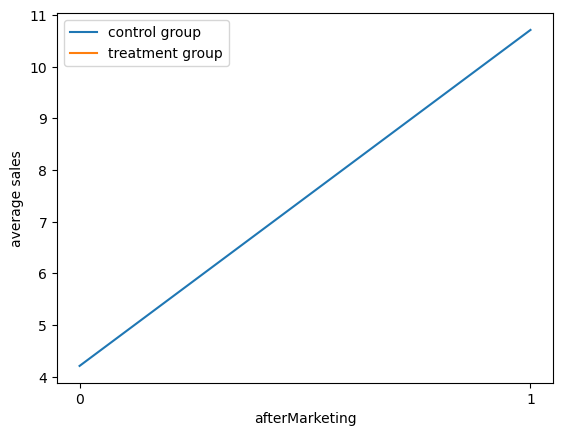

In [136]:
plt.plot([mean00, mean01], label ='control group')
plt.plot([mean10, mean11], label ='treatment group')
plt.legend()
plt.xlabel('afterMarketing')
plt.ylabel('average sales')
plt.xticks([0,1])
plt.show()

In [126]:
# Урок 55 Метрики, аналитика пользовательского поведения

In [80]:
import pandas as pd

data = {
    'CustomerID':[1, 2, 3, 4],
    'AveragePurchasevValue':[1000, 1500, 2000, 1200],
    'PurchaseFrequency': [10, 15, 20, 12],
    'CustomerLifeespanYears': [2, 3, 4, 1.5]
}

df = pd.DataFrame(data)
df

,CustomerID,AveragePurchasevValue,PurchaseFrequency,CustomerLifeespanYears
0,1,1000,10,2.0
1,2,1500,15,3.0
2,3,2000,20,4.0
3,4,1200,12,1.5


In [84]:
CLV = df['AveragePurchasevValue'].mean()* df['PurchaseFrequency'].mean() * df['CustomerLifeespanYears'].mean()
print(CLV)

53303.90625


In [85]:
# Кластеризация
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

data = {
    'AnnualSpend': [550, 610, 708, 880, 901, 1105, 1250, 1370],
    'Frequency': [11, 13, 13, 15, 19, 20, 22, 25]
}

df = pd.DataFrame(data)
df

,AnnualSpend,Frequency
0,550,11
1,610,13
2,708,13
3,880,15
4,901,19
5,1105,20
6,1250,22
7,1370,25


In [86]:
# масштабирование
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

In [88]:
# Кластеризация
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster']=kmeans.fit_predict(df_scaled)

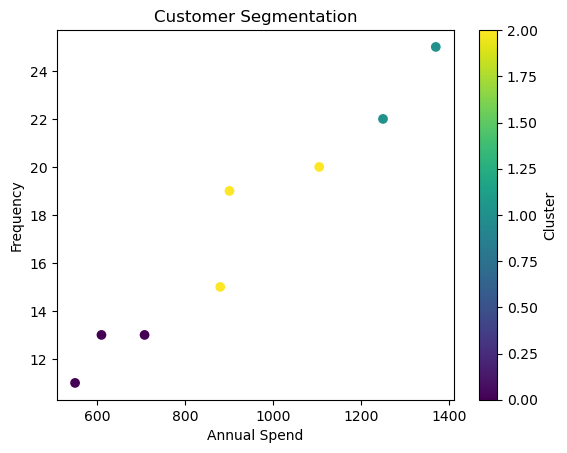

In [90]:
plt.scatter(df['AnnualSpend'], df['Frequency'], c=df['Cluster'], cmap='viridis')
plt.xlabel('Annual Spend')
plt.ylabel('Frequency')
plt.title('Customer Segmentation')
plt.colorbar(label='Cluster')
plt.show()

In [92]:
# Sample data
data = {
    'Year': [2020, 2021, 2022],
    'StartPeriodCustomers': [1000, 1200, 1100],
    'ChurnedCustomers': [50, 65, 60]
}

df = pd.DataFrame(data)
df

,Year,StartPeriodCustomers,ChurnedCustomers
0,2020,1000,50
1,2021,1200,65
2,2022,1100,60


In [97]:
# Подсчитаем отток
df['ChurnRate (%)'] = (df['ChurnedCustomers']/ df['StartPeriodCustomers'])* 100

df[['Year', 'ChurnRate (%)']]

,Year,ChurnRate (%)
0,2020,5.000000
1,2021,5.416667
2,2022,5.454545


In [102]:
# Sample data
data = {
    'Year': [2020, 2021, 2022],
    'MarketingCosts': [10000, 15000, 20000],
    'NewCustomers': [100, 150, 120]
}
df = pd.DataFrame(data)
df

,Year,MarketingCosts,NewCustomers
0,2020,10000,100
1,2021,15000,150
2,2022,20000,120


In [99]:
# Считаем САС
df['CAC'] = df['MarketingCosts']/ df['NewCustomers']

df[['Year', 'CAC']]

,Year,CAC
0,2020,1000.000000
1,2021,100.000000
2,2022,166.666667
